# Retrievals: Linearised Time-Series Retrievals

Written by [Evert Nasedkin](mailto:nasedkinevert@gmail.com?subject=[petitRADTRANS]%20Retrievals).

Please cite pRT's retrieval package [(Nasedkin et al. 2024)](https://ui.adsabs.harvard.edu/abs/2024JOSS....9.5875N/abstract) in addition to pRT [(Mollière et al. 2019)](https://ui.adsabs.harvard.edu/abs/2019A%26A...627A..67M/abstract) if you make use of the retrieval package for your work.

Brown dwarfs and directly imaged planets rotate, and as they do the spectrum we see changes: clouds, hot spots and chemical patches move in and out of view.
Time-resolved spectroscopy with JWST now measures this variability across the whole near-infrared at once.
In this tutorial we'll show how to retrieve *how the atmosphere changes* over a rotation, using the planetary-mass brown dwarf SIMP J013656.5+093347 (SIMP 0136 for short) as an example.

We'll go through the full process:

1. sketch the idea behind the linearised time-series model,
2. generate a synthetic SIMP 0136 time series, using trigonometric interpolation to make the time sampling exact,
3. retrieve the static atmosphere from the time-averaged spectrum,
4. measure the rotational modulation of the atmosphere, and compare it to what we put in.

**Please make sure to have worked through the ["Basic Retrieval Tutorial"](retrieval_basic.html) and the ["Emission Spectra Retrieval Tutorial"](retrieval_emission_tutorial.html) before looking at the material below.**
A more detailed description of the method, including the statistical model and the diagnostics that should accompany a published result, can be found on the ["Linearised Time-Series Retrievals"](../retrieval_linearised_time_series.html) page.

## The idea

Let's start with the problem. The simplest way to fit a time series is to let some atmospheric parameters vary sinusoidally in time, and fit everything at once.
Every time-varying parameter then brings along several new parameters (an amplitude and a phase for every harmonic), these are strongly correlated with each other and with the static atmosphere, and the samplers struggle to converge.
Each likelihood evaluation also needs many forward models, one for every point in time.

The key observation is that the variability is *small*: for SIMP 0136 the flux changes by a few percent at most.
For changes that small, the spectrum responds linearly to changes in the atmosphere, and we can write the log of the flux at wavelength $\lambda$ and time $t$ as

$$
\ln F(\lambda, t) \approx \ln F_\mathrm{ref}(\lambda) + \sum_p J_p(\lambda)\,\delta\theta_p(t),
\qquad
\delta\theta_p(t) = \sum_{k=1}^{K} \left[a_{pk}\cos(k\omega t) + b_{pk}\sin(k\omega t)\right].
$$

Here $F_\mathrm{ref}$ is the spectrum of a *reference* atmosphere, $\delta\theta_p(t)$ is how far parameter $p$ (a temperature, an abundance, ...) moves away from its reference value over the rotation, written as a short Fourier series with angular frequency $\omega = 2\pi/P_\mathrm{rot}$, and $J_p(\lambda) = \partial \ln F / \partial\theta_p$ is the **response spectrum** of that parameter: the fractional change in flux at every wavelength per unit change in the parameter.
pRT computes all of the response spectra together in a single forward-mode differentiation of the forward model, so this costs about as much as one ordinary forward model.

The important part is that the model is *linear* in the Fourier amplitudes $a_{pk}$ and $b_{pk}$.
With Gaussian priors and Gaussian noise, the posterior of a linear model can be written down exactly, so the amplitudes never need to be sampled: they are integrated out analytically, and the sampler only ever sees the reference atmosphere and the rotation period.
Once we know the reference atmosphere, the amplitudes and their uncertainties are recovered in closed form.

We'll do the retrieval in two stages:

- **Stage 1** retrieves the static atmosphere from the *time-averaged* spectrum. This is an ordinary pRT emission retrieval, set up exactly as in the other tutorials.
- **Stage 2** measures the modulation with the linearised model, using the stage 1 posterior as the reference atmosphere. Every wavelength's time average is removed exactly, so stage 2 uses only the information that stage 1 did not.

Why not fit both at once? A time series has hundreds of thousands of data points, while the time-averaged spectrum has only a few hundred.
In a single joint fit, the variability term dominates the likelihood and pulls the static atmosphere around through the *shape* of the response spectra, which is where the forward model is least reliable.
Splitting the problem keeps each part of the data doing what it is best at.

## Getting started

The marginal likelihood of the linearised model is compared at the level of a few nats on a number of order $10^5$, so **JAX must run in double precision**.
This has to be set before petitRADTRANS is imported, and pRT will raise an error if you forget.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)  # must come before importing petitRADTRANS

import matplotlib.pyplot as plt
import numpy as np
import tensorflow_probability.substrates.jax as tfp

from petitRADTRANS import physical_constants as cst
from petitRADTRANS.retrieval import Retrieval, RetrievalConfig, linearised
from petitRADTRANS.retrieval.models import gradient_profile_emission, make_linearised_time_series_model
from petitRADTRANS.retrieval.utils import process_spectrum_pipeline

tfpd = tfp.distributions

print(f"JAX devices: {jax.devices()}")

JAX devices: [CudaDevice(id=0)]


## SIMP 0136 and the observation

SIMP 0136 is a T2.5 brown dwarf with a mass of about 13 Jupiter masses [(Gagné et al. 2017)](https://ui.adsabs.harvard.edu/abs/2017ApJ...841L...1G/abstract), at a distance of 6.1 pc.
It rotates in about 2.4 hours and was one of the first brown dwarfs found to be strongly variable [(Artigau et al. 2009)](https://ui.adsabs.harvard.edu/abs/2009ApJ...701.1534A/abstract).
It was monitored with the JWST NIRSpec PRISM for about three hours [(McCarthy et al. 2025)](https://ui.adsabs.harvard.edu/abs/2025ApJ...981L..22M/abstract), giving 573 spectra between 0.9 and 5.3 $\mu$m.

In this tutorial we'll build a synthetic dataset with the same design: the same number of epochs and cadence, a similar wavelength grid and resolving power, and a similar noise level.
This way we know the right answer, and we can check that the retrieval finds it.
At the end of the notebook we show what changes when you use real data.

Throughout, times are in seconds, wavelengths in microns and fluxes in W m$^{-2}$ $\mu$m$^{-1}$.

In [2]:
# The observation design, matching the JWST NIRSpec PRISM monitoring of SIMP 0136
n_epochs = 573
cadence = 18.3  # seconds between integrations
times = np.arange(n_epochs) * cadence  # roughly 2.9 hours, about 1.2 rotations

wavelengths = np.geomspace(0.91, 5.29, 300)  # micron
# An approximate PRISM resolving power: about 30 at 1.2 micron, rising to about 300 at 5 micron
resolving_power = np.interp(
    wavelengths, [0.9, 1.2, 2.0, 3.0, 4.0, 5.3], [80.0, 30.0, 60.0, 110.0, 170.0, 320.0]
)

relative_noise = 0.0045  # 0.45% per spectral channel per integration, typical for these data

print(f"{n_epochs} epochs spanning {times[-1] / 3600:.2f} h, {wavelengths.size} wavelength channels")

573 epochs spanning 2.91 h, 300 wavelength channels


## The forward model

Both retrieval stages and the data generator must use the *same* static forward model, so let's write it once as a function that returns a `RetrievalConfig` with the opacities and the static parameters already added.

We use the gradient temperature profile of [Zhang et al. (2023)](https://ui.adsabs.harvard.edu/abs/2023AJ....166..198Z/abstract), via the built-in `gradient_profile_emission` model, with free chemistry.
The temperature gradient $\mathrm{d}\ln T/\mathrm{d}\ln P$ is set at `N_layers` nodes spaced evenly in log pressure: `PTslope_1` at the bottom of the atmosphere, up to `PTslope_6` at the top, and the profile is integrated upwards from `T_bottom` at the bottom of the grid.
The distance and the mass are held fixed, and the radius gets a Gaussian prior.

To keep this tutorial quick we leave out clouds and scattering. Clouds are added exactly as in the ["Emission Spectra Retrieval Tutorial"](retrieval_emission_tutorial.html).

In [3]:
pressures = np.logspace(-4, 2, 80)  # bar
n_layers = 6
line_species = [
    "H2O__POKAZATEL",
    "CO-NatAbund",
    "CH4__MM",
    "CO2",
    "H2S",
    "Na__NewAllard",
    "K__Allard",
]


def static_configuration(retrieval_name):
    # A RetrievalConfig holding everything about the static atmosphere: opacities, fixed values and priors.
    configuration = RetrievalConfig(
        retrieval_name=retrieval_name,
        run_mode="retrieval",
        sampler_type="optimal_estimation",  # used by stage 1; stage 2 needs no sampler
        pressures=pressures,
        scattering_in_emission=False,
    )
    configuration.set_rayleigh_species(["H2", "He"])
    configuration.set_continuum_opacities(["H2--H2", "H2--He"])
    # Free chemistry: one vertically constant mass fraction per species, log-uniform between 1e-10 and 0.1
    configuration.set_line_species(
        line_species,
        use_equilibrium_chemistry=False,
        free_mass_fraction_limits=(-10.0, -1.0),
    )

    # Fixed parameters: geometry and the layout of the temperature profile
    configuration.add_parameter(name="system_distance", is_free_parameter=False, value=6.12 * cst.pc)
    configuration.add_parameter(name="planet_mass", is_free_parameter=False, value=12.7 * cst.m_jup)
    configuration.add_parameter(name="N_layers", is_free_parameter=False, value=n_layers)
    configuration.add_parameter(name="top_of_atmosphere_pressure", is_free_parameter=False, value=-4.0)
    configuration.add_parameter(name="bottom_of_atmosphere_pressure", is_free_parameter=False, value=2.0)

    # Free parameters
    configuration.add_parameter(
        name="planet_radius",
        is_free_parameter=True,
        distribution=tfpd.Normal(loc=1.0 * cst.r_jup_mean, scale=0.2 * cst.r_jup_mean),
    )
    configuration.add_parameter(
        name="T_bottom",
        is_free_parameter=True,
        distribution=tfpd.Uniform(low=1000.0, high=5000.0),
    )
    for node in range(1, n_layers + 1):
        configuration.add_parameter(
            name=f"PTslope_{node}",
            is_free_parameter=True,
            distribution=tfpd.Normal(loc=0.1, scale=0.1),
        )
    return configuration


fixed_values = {
    "system_distance": 6.12 * cst.pc,
    "planet_mass": 12.7 * cst.m_jup,
    "N_layers": n_layers,
    "top_of_atmosphere_pressure": -4.0,
    "bottom_of_atmosphere_pressure": 2.0,
}

## A synthetic SIMP 0136 time series

### The atmosphere we put in

First we choose the true static atmosphere: a temperature of about 1200 K at 1 bar and abundances typical of an early T dwarf.

In [4]:
true_static = {
    "planet_radius": 0.95 * cst.r_jup_mean,
    "T_bottom": 2700.0,
    "PTslope_1": 0.22,
    "PTslope_2": 0.17,
    "PTslope_3": 0.12,
    "PTslope_4": 0.04,
    "PTslope_5": 0.01,
    "PTslope_6": 0.0,
    "H2O__POKAZATEL": -2.7,  # log10 mass fractions
    "CO-NatAbund": -2.4,
    "CH4__MM": -3.6,
    "CO2": -5.5,
    "H2S": -3.0,
    "Na__NewAllard": -4.4,
    "K__Allard": -5.5,
}

Then we choose how the atmosphere changes as SIMP 0136 rotates.
We'll let three parameters vary: the temperature at the bottom of the atmosphere, the temperature gradient around 0.4 bar (`PTslope_3`), which sets how warm the photosphere is, and the water abundance.
Each of them follows a Fourier series with two harmonics of the rotation period, and the amplitudes are chosen so that the flux varies by about 2%, as observed for SIMP 0136.

In [5]:
true_period = 2.36 * 3600.0  # seconds
n_harmonics = 2

# For every varying parameter: [(cos, sin) amplitudes of harmonic 1, (cos, sin) amplitudes of harmonic 2]
true_modulation = {
    "T_bottom": [(3.5, 2.3), (-1.4, 1.2)],  # K
    "PTslope_3": [(0.00045, -0.0003), (0.00018, 0.0)],
    "H2O__POKAZATEL": [(0.003, 0.0018), (0.0, -0.0012)],  # dex
}


def true_parameters_at(time):
    # The true atmosphere at a given time: the static values plus the Fourier series.
    values = dict(true_static)
    omega = 2.0 * np.pi / true_period

    for name, harmonics in true_modulation.items():
        for k, (cos_amplitude, sin_amplitude) in enumerate(harmonics, start=1):
            values[name] += cos_amplitude * np.cos(k * omega * time) + sin_amplitude * np.sin(k * omega * time)

    return values

### Computing spectra on the data grid

To compute model spectra exactly as the retrieval will see them, we set up a configuration with a placeholder dataset on our wavelength grid.
`calculate_forward_model` computes the spectrum at the model resolution, and `process_spectrum_pipeline` applies the same convolution and rebinning to the data grid that the retrieval applies when it computes the likelihood.

In [6]:
generator_configuration = static_configuration("SIMP0136_generator")
generator_configuration.add_data(
    name="NIRSpec",
    model_generating_function=gradient_profile_emission,
    wavelengths=wavelengths,
    spectrum=np.ones_like(wavelengths),  # placeholder, only the grid matters here
    uncertainties=np.ones_like(wavelengths),
    data_resolution=resolving_power,
    model_resolution=200,
    wavelength_boundaries=(0.88, 5.4),
)
generator = Retrieval(generator_configuration, output_directory="./retrievals/time_series/runs")


def spectrum_on_data_grid(parameter_values):
    # The model spectrum for the given parameter values, convolved and rebinned onto the data grid.
    model_wavelengths, model_flux = generator.calculate_forward_model(parameters=parameter_values, data="NIRSpec")

    return np.asarray(
        process_spectrum_pipeline(
            model_wavelengths,
            model_flux,
            generator_configuration.data["NIRSpec"],
            {**parameter_values, **fixed_values},
            "NIRSpec",
        )
    )

Setting up Radtrans object for data 'NIRSpec'...
Loading Radtrans opacities...
 Loading line opacities of species 'H2O__POKAZATEL.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R200_0.3-50.0mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO-NatAbund.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R200_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CH4__MM.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__MM.R200_0.3-50.0mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO2.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__Dozen.R200_0.3-50.0mu.ktable.petitRADTRANS.h5'... Done.
 Loading l

### Trigonometric interpolation

We now need a spectrum at every one of the 573 epochs. We could call the forward model 573 times, but there is a much cheaper way.

Over one rotation the spectrum is a *periodic* function of time, and it only contains a few harmonics of the rotation frequency.
When the atmospheric parameters contain harmonics up to $K$, the spectrum, which depends on them non-linearly, contains harmonics up to about $2K$.
A periodic signal with $2K$ harmonics is fully determined by its values at $4K+1$ distinct rotational phases.
So we compute the spectrum at a handful of **node phases** across one rotation, fit the harmonics to them, and evaluate the fit at every epoch.
`linearised.trigonometric_resampling_matrix` builds the matrix that does all of this in one step: multiplying it with the node spectra gives the spectra at all of the epochs.

Here we use 12 nodes for $2K = 4$ harmonics; using more nodes than the minimum averages down any weak higher-order content.
Make sure the node phases are all distinct: a grid that includes both 0 and $P_\mathrm{rot}$ repeats a phase, and pRT will raise an error.

In [7]:
n_nodes = 12
node_times = np.linspace(0.0, true_period, n_nodes, endpoint=False)  # distinct phases over one rotation
node_spectra = np.array([spectrum_on_data_grid(true_parameters_at(t)) for t in node_times])

resampling_matrix = np.asarray(
    linearised.trigonometric_resampling_matrix(node_times, times, true_period, 2 * n_harmonics)
)
true_spectra = resampling_matrix @ node_spectra  # shape (n_epochs, n_wavelengths)

print(f"node spectra: {node_spectra.shape}, resampling matrix: {resampling_matrix.shape}, "
      f"time series: {true_spectra.shape}")

node spectra: (12, 300), resampling matrix: (573, 12), time series: (573, 300)


Let's check how well this works at an epoch that is not one of the nodes, by comparing with a direct calculation of the forward model.
For comparison we also try the obvious alternative, linear interpolation between the node spectra.

In [8]:
epoch = 250
direct = spectrum_on_data_grid(true_parameters_at(times[epoch]))

phase_time = times[epoch] % true_period
linear = np.array(
    [
        np.interp(phase_time, np.append(node_times, true_period), np.append(node_spectra[:, i], node_spectra[0, i]))
        for i in range(wavelengths.size)
    ]
)

print(f"trigonometric interpolation: largest relative error {np.max(np.abs(true_spectra[epoch] / direct - 1)):.1e}")
print(f"linear interpolation:        largest relative error {np.max(np.abs(linear / direct - 1)):.1e}")
print(f"noise on the time-averaged spectrum: {relative_noise / np.sqrt(n_epochs):.1e}")

trigonometric interpolation: largest relative error 5.6e-07
linear interpolation:        largest relative error 6.9e-04
noise on the time-averaged spectrum: 1.9e-04


The trigonometric interpolation reproduces the forward model to better than one part in a million, while straight lines between the nodes are wrong by several parts in $10^4$: more than the noise on the time-averaged spectrum.
That matters: the error of linear interpolation grows with the signal itself, so it does not average away and it biases exactly the amplitudes we want to measure.

pRT uses the same technique inside retrievals that compute the full time series with `time_series_gradient_emission`: pass `time_interpolation="trigonometric"` to `RetrievalConfig.add_time_series_data` to use it there.

### Adding noise

Finally, we add Gaussian noise at the level of the real observations.

In [9]:
rng = np.random.default_rng(136)
uncertainties = relative_noise * true_spectra
observed_spectra = true_spectra + uncertainties * rng.standard_normal(true_spectra.shape)

Let's have a look at the time series.
Dividing every spectrum by the time-averaged spectrum removes the overall spectral shape and shows the variability: the top panel shows how this changes with wavelength and time, and the bottom panel shows light curves integrated over a few wavelength bands.
Note how different parts of the spectrum vary differently: this is the information that tells us *which* atmospheric parameters change.

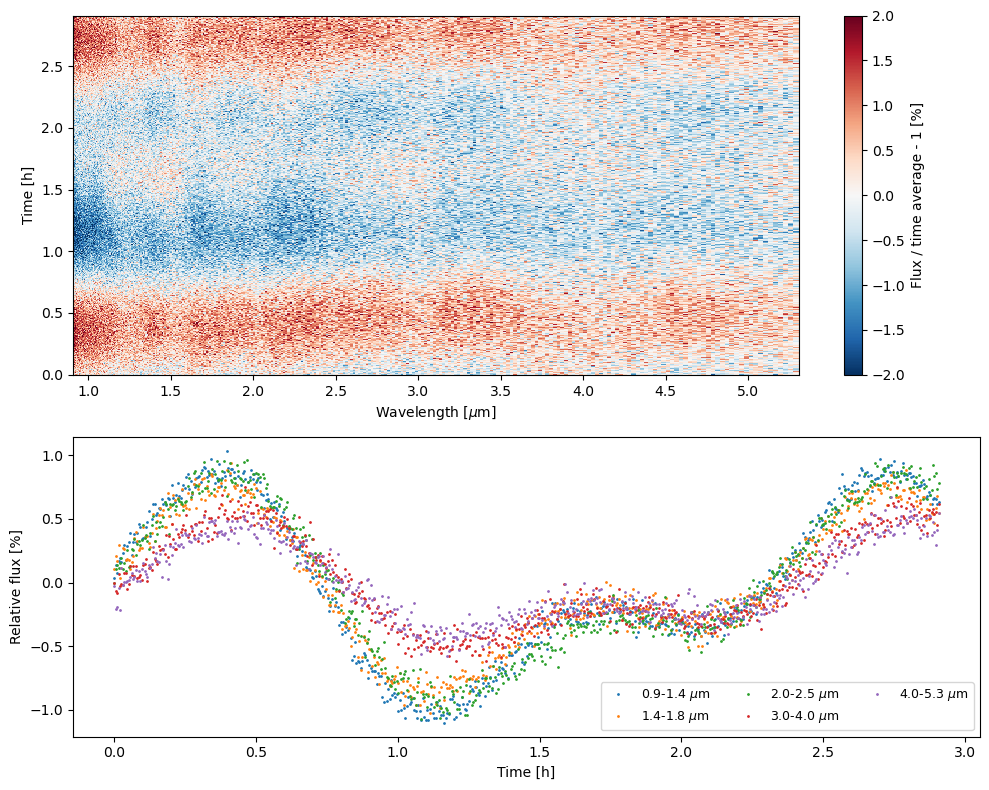

In [10]:
mean_divided = observed_spectra / observed_spectra.mean(axis=0)
hours = times / 3600.0

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=False, gridspec_kw={"height_ratios": [1.2, 1.0]})

image = axes[0].pcolormesh(
    wavelengths, hours, 100.0 * (mean_divided - 1.0), cmap="RdBu_r", vmin=-2.0, vmax=2.0, shading="auto"
)
fig.colorbar(image, ax=axes[0], label="Flux / time average - 1 [%]")
axes[0].set_xlabel(r"Wavelength [$\mu$m]")
axes[0].set_ylabel("Time [h]")

bands = ((0.9, 1.4), (1.4, 1.8), (2.0, 2.5), (3.0, 4.0), (4.0, 5.3))

for low, high in bands:
    in_band = (wavelengths >= low) & (wavelengths < high)
    light_curve = observed_spectra[:, in_band].sum(axis=1)
    axes[1].plot(hours, 100.0 * (light_curve / light_curve.mean() - 1.0), ".", markersize=2,
                 label=rf"{low}-{high} $\mu$m")

axes[1].set_xlabel("Time [h]")
axes[1].set_ylabel("Relative flux [%]")
axes[1].legend(ncol=3, fontsize=9)
fig.tight_layout()

## Stage 1: the static atmosphere

### The time-averaged spectrum

Stage 1 is an ordinary emission retrieval on the time-averaged spectrum.
We average in log space, because stage 2 works with the logarithm of the flux and the two stages must describe the same reference atmosphere.
Each epoch is weighted by its inverse variance; `linearised.log_observation` returns the log flux and the variance of the log flux for every point.

In [11]:
log_flux, log_variance = linearised.log_observation(observed_spectra, uncertainties)  # (n_wavelengths, n_epochs)
weights = 1.0 / np.asarray(log_variance)

mean_log_flux = (np.asarray(log_flux) * weights).sum(axis=1) / weights.sum(axis=1)
mean_spectrum = np.exp(mean_log_flux)
mean_uncertainty = mean_spectrum / np.sqrt(weights.sum(axis=1))

print(f"median relative uncertainty of the time-averaged spectrum: {np.median(mean_uncertainty / mean_spectrum):.1e}")

median relative uncertainty of the time-averaged spectrum: 1.9e-04


Averaging 573 spectra makes the time-averaged spectrum extremely precise: about 0.02% per channel.
No forward model is that accurate for a real brown dwarf, so for real data the retrieval would then be dominated by the model error rather than by the data.
We therefore add a fractional error floor: the parameter `uncertainty_fractional_floor` is the log10 of a fraction of the observed flux that is added in quadrature to the uncertainties.
For real data the floor is retrieved together with the atmosphere; for SIMP 0136 it settles at around ten percent.
Our synthetic data are made with the same model that we fit, so a retrieved floor would drop to its lower limit, and leave a likelihood far sharper than any real retrieval would see.
We fix it at 1% instead, an optimistic but realistic model error.

In [12]:
stage_1_configuration = static_configuration("SIMP0136_synthetic_static")
stage_1_configuration.add_parameter(
    name="uncertainty_fractional_floor",
    is_free_parameter=False,
    value=-2.0,  # log10 of the fraction: a 1% floor. For real data, make it free, e.g. Uniform(-5, -1)
)
stage_1_configuration.add_data(
    name="NIRSpec_mean",
    model_generating_function=gradient_profile_emission,
    wavelengths=wavelengths,
    spectrum=mean_spectrum,
    uncertainties=mean_uncertainty,
    data_resolution=resolving_power,
    model_resolution=200,
    wavelength_boundaries=(0.88, 5.4),
)

output_directory = "./retrievals/time_series/runs"
stage_1 = Retrieval(
    configuration=stage_1_configuration,
    output_directory=output_directory,
    evaluate_sample_spectra=False,
    use_prt_plot_style=True,
)

free_parameters = [name for name, p in stage_1_configuration.parameters.items() if p.is_free_parameter]
print(f"{len(free_parameters)} free parameters: {free_parameters}")

Setting up Radtrans object for data 'NIRSpec_mean'...
Loading Radtrans opacities...
 Loading line opacities of species 'H2O__POKAZATEL.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R200_0.3-50.0mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO-NatAbund.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R200_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CH4__MM.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__MM.R200_0.3-50.0mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO2.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__Dozen.R200_0.3-50.0mu.ktable.petitRADTRANS.h5'... Done.
 Load

### Running stage 1

Even with the error floor, the time-averaged spectrum constrains the static atmosphere very tightly, and nested samplers struggle with a posterior this narrow: they need many hours, and can still miss it.
We therefore use **optimal estimation** (`sampler_type="optimal_estimation"`, see the [sampler documentation](../retrieval_samplers.rst)).
It maximises the posterior with gradients, from several starting points (`n_starts`), and refines the best maximum with L-BFGS.
It then approximates the posterior as a Gaussian, from the curvature at the maximum (the Laplace approximation), and draws samples from it, which is all that stage 2 needs.

Restarting matters: most starting points stall far from the best fit, and only a few reach it.
The Laplace approximation is a good description of a single, well-defined maximum like this one, but it gives no Bayesian evidence and it cannot describe a posterior with several separated solutions.
For real data, use the optimal estimate as the starting point of a sampler, as in the ["Advanced NUTS Retrieval Tutorial"](retrieval_NUTS_advanced_emission_tutorial.html).

Set `run_retrieval = True` to run it; it takes a little over two minutes on an NVIDIA A100 GPU.
The default stays `False`, in which case we load the results of a run that we did with exactly these settings, which are included with the documentation.

In [13]:
run_retrieval = False

In [14]:
if run_retrieval:
    stage_1.run(
        n_starts=8,  # random restarts around the prior median
        n_steps=1000,  # optimiser steps per start
        lbfgs_polish_steps=300,  # L-BFGS refinement of the best maximum
        compute_laplace=True,
        n_posterior_samples=2000,
        seed=136,
    )

Let's read in the posterior and compare it to the atmosphere we put in.
There is one subtlety: the time-averaged spectrum measures the atmosphere averaged over the *observed* epochs.
Our 2.9 hours cover 1.23 rotations, not a whole number, so the Fourier series do not average to zero over the observation, and the parameters that vary are slightly offset from their static values.
The values to compare with are therefore the true parameters averaged over the epochs.
The same average is the reference atmosphere of stage 2, so the two stages describe the same atmosphere.

In [15]:
sample_dict, parameter_dict = stage_1.get_samples(output_directory=output_directory)
stage_1_samples = sample_dict[stage_1_configuration.retrieval_name]  # (n_parameters + 1, n_samples): the last row is ln L
stage_1_names = parameter_dict[stage_1_configuration.retrieval_name]

# The true atmosphere averaged over the observed epochs
true_at_epochs = [true_parameters_at(t) for t in times]
true_time_average = {name: np.mean([values[name] for values in true_at_epochs]) for name in true_static}

for name in true_modulation:
    print(f"{name}: time average - static value = {true_time_average[name] - true_static[name]:.2g}")

print(f"\n{stage_1_samples.shape[1]} posterior samples\n")
print(f"{'parameter':<30s}{'truth':>12s}{'median':>12s}{'16-84% range':>28s}")

for row, name in enumerate(stage_1_names):
    low, median, high = np.percentile(stage_1_samples[row], [16, 50, 84])
    scale = cst.r_jup_mean if name == "planet_radius" else 1.0
    truth = true_time_average.get(name, np.nan) / scale
    print(f"{name:<30s}{truth:12.4g}{median / scale:12.4g}   [{low / scale:10.4g}, {high / scale:10.4g}]")

T_bottom: time average - static value = 0.85
PTslope_3: time average - static value = 2.6e-05
H2O__POKAZATEL: time average - static value = 0.00044

2000 posterior samples

parameter                            truth      median                16-84% range
H2O__POKAZATEL                        -2.7      -2.699   [    -2.702,     -2.696]
CO-NatAbund                           -2.4        -2.4   [    -2.411,     -2.389]
CH4__MM                               -3.6      -3.599   [    -3.603,     -3.595]
CO2                                   -5.5        -5.5   [    -5.512,     -5.488]
H2S                                     -3      -3.002   [    -3.017,     -2.988]
Na__NewAllard                         -4.4        -4.4   [    -4.408,     -4.391]
K__Allard                             -5.5        -5.5   [     -5.51,      -5.49]
planet_radius                         0.95        0.95   [    0.9483,     0.9517]
T_bottom                              2701        2700   [      2682,       2720]
PTslop

The usual pRT plots work as for any other retrieval, for example the P-T profile:


Plotting PT profiles
Not in evaluate mode. Changing run mode to evaluate.


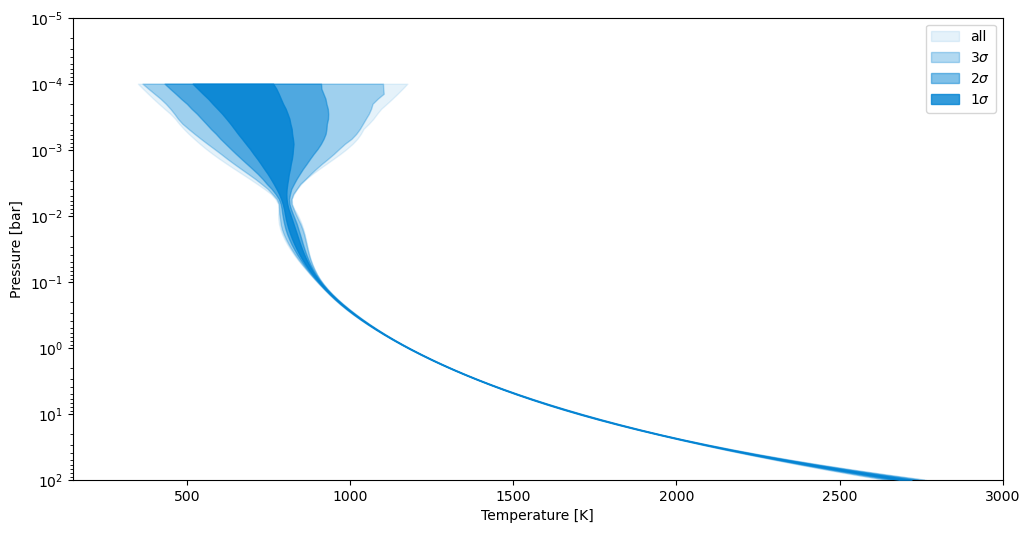

In [16]:
figure, ax = stage_1.plot_pt(sample_dict, stage_1_names, refresh=True)

## Stage 2: the modulation

### The linearised dataset

For stage 2, the model function must return the reference spectrum *and* its response spectra.
`make_linearised_time_series_model` wraps any runtime-native model, here `gradient_profile_emission`, to do exactly that, using forward-mode differentiation.

The time series is added with `add_linearised_time_series_data`. The arguments that matter most are:

- `modulated_parameters`: the parameters allowed to vary, each with the prior standard deviation of its Fourier amplitudes. The widths enter the marginal likelihood, so they are part of the model and must always be given.
- `n_harmonics`: the number of harmonics of the rotation frequency in the Fourier series.
- `static_offset_scale=None`: an infinitely wide offset at every wavelength, which removes each wavelength's time average exactly. This is what makes stage 2 independent of the stage 1 fit.
- `reference_bin=0, n_phase_bins=1`: the reference atmosphere is the time-averaged atmosphere over all epochs, which is the one stage 1 retrieved.
- `period_parameter`: the parameter holding the rotation period, in seconds.

In [17]:
modulated_parameters = {
    "T_bottom": 50.0,  # K
    "PTslope_3": 0.02,
    "H2O__POKAZATEL": 0.2,  # dex
}

stage_2_configuration = static_configuration("SIMP0136_synthetic_modulation")
stage_2_configuration.add_parameter(
    name="period",
    is_free_parameter=True,
    distribution=tfpd.Uniform(low=2.0 * 3600.0, high=2.8 * 3600.0),
)
stage_2_configuration.parameters["period"].value = 2.4 * 3600.0  # the nominal period, from the literature

stage_2_configuration.add_linearised_time_series_data(
    name="NIRSpec_time_series",
    observation_times=times,
    model_generating_function=make_linearised_time_series_model(gradient_profile_emission),
    modulated_parameters=modulated_parameters,
    n_harmonics=n_harmonics,
    reference_bin=0,
    n_phase_bins=1,
    period_parameter="period",
    nominal_period=2.4 * 3600.0,
    static_offset_scale=None,
    wavelengths=wavelengths,
    spectrum=observed_spectra,  # (n_epochs, n_wavelengths)
    uncertainties=uncertainties,
    data_resolution=resolving_power,
    model_resolution=200,
    wavelength_boundaries=(0.88, 5.4),
)

stage_2 = Retrieval(
    configuration=stage_2_configuration,
    output_directory=output_directory,
    evaluate_sample_spectra=False,
    use_prt_plot_style=True,
)

[linearised] 'NIRSpec_time_series': 3 modulated parameters x 4 amplitudes = 12 marginalised analytically; reference set 573 epochs of bin 0/1; offset scale infinite
Setting up Radtrans object for data 'NIRSpec_time_series'...
Loading Radtrans opacities...
 Loading line opacities of species 'H2O__POKAZATEL.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R200_0.3-50.0mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO-NatAbund.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R200_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CH4__MM.R200' from file '/u/nnas/packages/petitRADTRANS/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__MM.R200_0.3-50.0mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'CO2.R200' from fil

### What do the response spectra look like?

Before measuring anything, it's worth looking at the response spectra $J_p(\lambda)$ at the best-fit stage 1 atmosphere.
They show how each modulated parameter changes the spectrum, and therefore which parts of the spectrum measure it.
If two response spectra look alike, the data can only measure a combination of the two parameters.

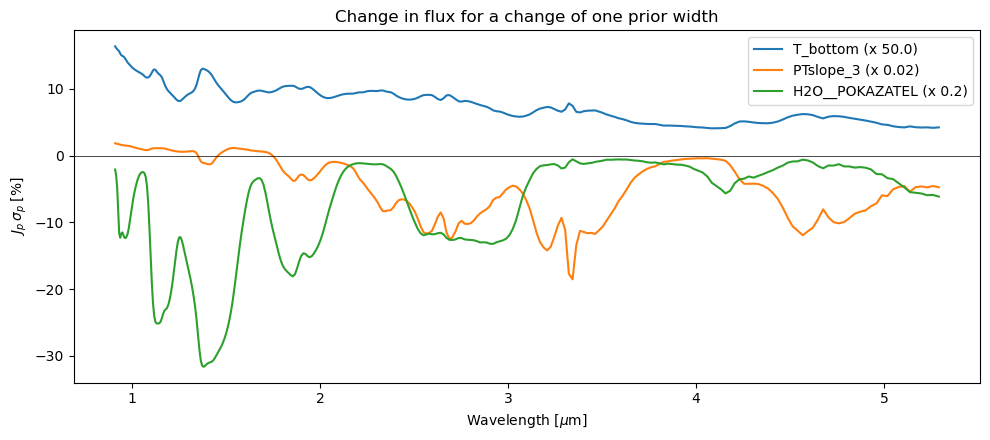

In [18]:
best_fit = dict(zip(stage_1_names, stage_1_samples[:-1, np.argmax(stage_1_samples[-1])]))

model_wavelengths, model_flux, auxiliary_outputs = stage_2.calculate_forward_model(
    parameters={**best_fit, "period": 2.4 * 3600.0}, data="NIRSpec_time_series"
)
flux_jacobian = np.asarray(auxiliary_outputs["flux_jacobian"])  # (n_model_wavelengths, n_modulated)

# Project the reference spectrum and the flux derivatives onto the data grid, then take the ratio
reference = spectrum_on_data_grid(best_fit)
fig, ax = plt.subplots(figsize=(10, 4.5))

for column, (name, width) in enumerate(modulated_parameters.items()):
    projected = np.asarray(
        process_spectrum_pipeline(
            model_wavelengths, flux_jacobian[:, column], generator_configuration.data["NIRSpec"],
            {**best_fit, **fixed_values}, "NIRSpec",
        )
    )
    # Scaled to the prior width, so that all curves are on a comparable footing
    ax.plot(wavelengths, 100.0 * width * projected / reference, label=f"{name} (x {width})")

ax.axhline(0.0, color="k", lw=0.5)
ax.set_xlabel(r"Wavelength [$\mu$m]")
ax.set_ylabel(r"$J_p\,\sigma_p$ [%]")
ax.set_title("Change in flux for a change of one prior width")
ax.legend()
fig.tight_layout()

### The rotation period

The period enters the model only through the Fourier series, not through the forward model.
Let's scan it: at every trial period, `calculate_modulation_posterior` solves for the amplitudes and returns the marginal likelihood $\ln Z$ of the time series, with the amplitudes integrated out.
Each call evaluates the forward model and its derivatives once, so a coarse grid takes only a minute or so.

best period: 2.360 h (truth 2.360 h)


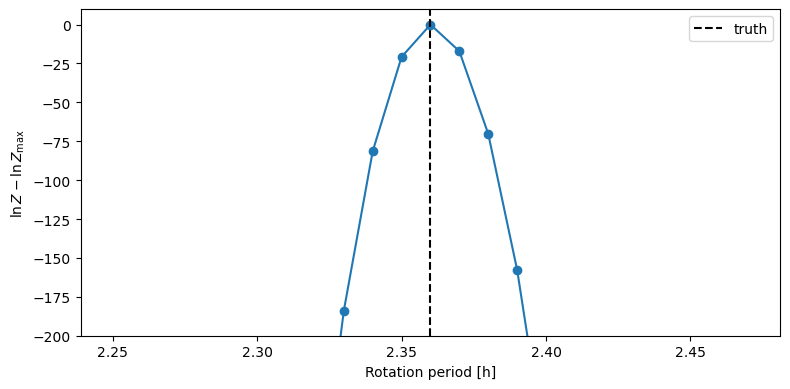

In [19]:
trial_periods = np.linspace(2.25, 2.47, 23) * 3600.0
log_evidence = np.array(
    [
        float(stage_2.calculate_modulation_posterior(parameters={**best_fit, "period": period})["log_evidence"])
        for period in trial_periods
    ]
)
best_period = trial_periods[np.argmax(log_evidence)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trial_periods / 3600.0, log_evidence - log_evidence.max(), "o-")
ax.axvline(true_period / 3600.0, color="k", ls="--", label="truth")
ax.set_xlabel("Rotation period [h]")
ax.set_ylabel(r"$\ln Z - \ln Z_\mathrm{max}$")
ax.set_ylim(-200, 10)
ax.legend()
fig.tight_layout()

print(f"best period: {best_period / 3600:.3f} h (truth {true_period / 3600:.3f} h)")

The marginal likelihood is sharply peaked at the true period.
For a real measurement you would refine the grid around the peak, or let the period be a free parameter of the sampler; here we simply keep the best value of the grid.

### The amplitudes at one reference atmosphere

At a given reference atmosphere and period, the posterior of the amplitudes is exactly Gaussian.
`calculate_modulation_posterior` returns its mean and covariance, together with the resulting change of every parameter over time, `excursion`, and its uncertainty.

In [20]:
posterior = stage_2.calculate_modulation_posterior(parameters={**best_fit, "period": best_period})

amplitudes = np.asarray(posterior["amplitudes"])  # (n_modulated, 2 * n_harmonics)
amplitude_errors = np.sqrt(np.diag(np.asarray(posterior["covariance"]))).reshape(amplitudes.shape)

print(f"columns per parameter: {[column.split(':')[1] for column in posterior['column_names'][:2 * n_harmonics]]}\n")

for row, name in enumerate(posterior["response_names"]):
    truth = np.ravel(true_modulation[name])
    print(f"{name}")
    print(f"   truth     {np.array2string(truth, precision=5, suppress_small=True)}")
    print(f"   retrieved {np.array2string(amplitudes[row], precision=5, suppress_small=True)}")
    print(f"   +-        {np.array2string(amplitude_errors[row], precision=5, suppress_small=True)}")

columns per parameter: ['c1', 's1', 'c2', 's2']

T_bottom
   truth     [ 3.5  2.3 -1.4  1.2]
   retrieved [ 3.51729  2.31387 -1.38982  1.18618]
   +-        [0.01684 0.01701 0.0166  0.01687]
PTslope_3
   truth     [ 0.00045 -0.0003   0.00018  0.     ]
   retrieved [ 0.00046 -0.0003   0.00018 -0.     ]
   +-        [0.00001 0.00001 0.00001 0.00001]
H2O__POKAZATEL
   truth     [ 0.003   0.0018  0.     -0.0012]
   retrieved [ 0.00305  0.00178  0.00003 -0.00123]
   +-        [0.00004 0.00004 0.00004 0.00004]


The amplitudes are recovered close to the values we put in, mostly within one or two standard deviations.
But note that this result is *conditional* on one particular reference atmosphere, the best fit of stage 1.
The amplitudes also depend on the reference atmosphere, and in real retrievals often more than on the noise in the data, so uncertainties like these can be far too small.

### The full modulation posterior

To include the uncertainty of the reference atmosphere, we solve for the amplitudes at many draws from the stage 1 posterior, and combine the results.
Because every draw contributes an exact Gaussian rather than a single sample, this needs far fewer draws than sampling the amplitudes would.
The total covariance then splits into two parts: the **statistical** part, from the noise in the data, and the **reference-state** part, from not knowing the static atmosphere exactly.

`plot_modulation` does all of this and plots the result, keeping the two uncertainties separate.
It takes the stage 1 samples, here with the best period added as one more parameter.

Not in evaluate mode. Changing run mode to evaluate.

Plotting the modulation of 'NIRSpec_time_series'
  solving reference state 50/50
  T_bottom: peak-to-peak 10.43, median total uncertainty 0.03145
  PTslope_3: peak-to-peak 0.001249, median total uncertainty 9.816e-06
  H2O__POKAZATEL: peak-to-peak 0.007841, median total uncertainty 6.323e-05


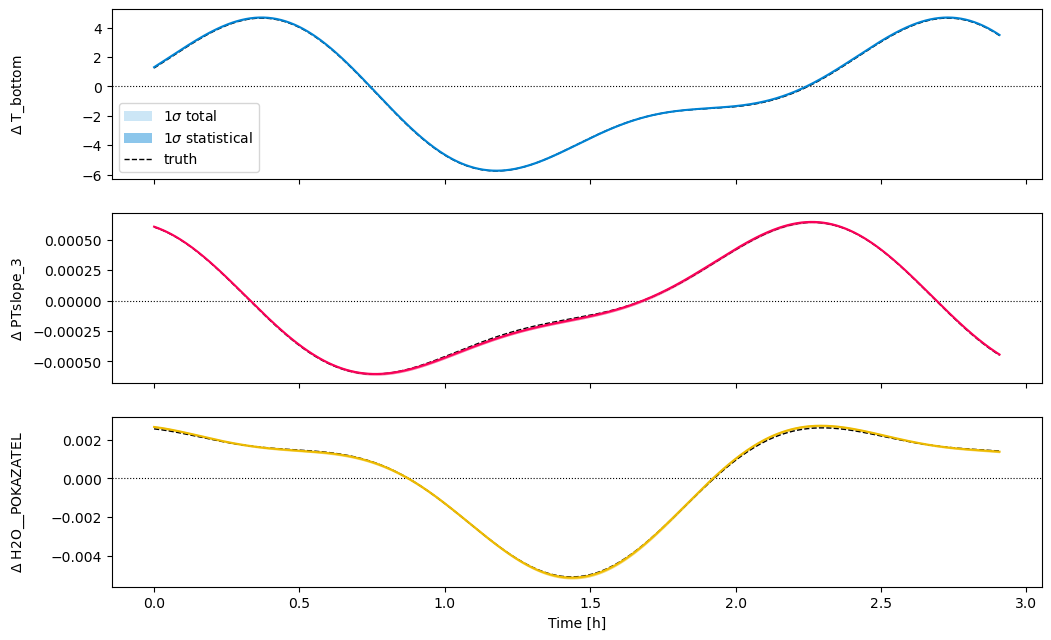

In [21]:
n_samples = stage_1_samples.shape[1]
stage_2_samples = np.vstack([stage_1_samples[:-1], np.full((1, n_samples), best_period)])
stage_2_names = list(stage_1_names) + ["period"]

np.random.seed(136)  # the reference atmospheres are drawn at random from the stage 1 posterior
figure, axes = stage_2.plot_modulation(
    sample_dict={stage_2_configuration.retrieval_name: stage_2_samples},
    parameters_read=stage_2_names,
    n_reference_samples=50,
    refresh=True,
)

# Overplot the truth: the true change of every parameter, relative to its time average
omega = 2.0 * np.pi / true_period

for ax, name in zip(axes, modulated_parameters):
    true_change = sum(
        a * np.cos(k * omega * times) + b * np.sin(k * omega * times)
        for k, (a, b) in enumerate(true_modulation[name], start=1)
    )
    ax.plot(hours, true_change - true_change.mean(), "k--", lw=1.0, label="truth")

axes[0].legend()
plt.show()

The retrieved modulation follows the injected one (dashed) closely, mostly within one or two standard deviations.
Both bands are so narrow here that they hide behind the lines: the uncertainties are less than 1% of the modulation.
The reference-state term also adds little in this example, because the time-averaged spectrum pins the static atmosphere down tightly, and our model describes the synthetic atmosphere exactly.
For the real SIMP 0136, where the forward model is imperfect and the stage 1 posterior is much wider, the reference-state term is often the larger of the two, which is why the conditional uncertainties of a single reference atmosphere should never be quoted on their own.

If you want the numbers rather than a figure, call `calculate_modulation_posterior` at each draw yourself, and combine the results with `linearised.mixture_moments`, which returns the combined mean, the total covariance and its reference-state part.

The amplitudes of different parameters are correlated, because their response spectra overlap.
`plot_modulation_correlation` shows these correlations, which appear in no corner plot since the amplitudes are never sampled.
The upper panel is the total correlation; the lower panel splits it into the part due to the noise (below the diagonal) and the part due to the uncertain reference atmosphere (above it).
It reuses the amplitudes that `plot_modulation` just solved for.


Plotting the amplitude correlations of 'NIRSpec_time_series'


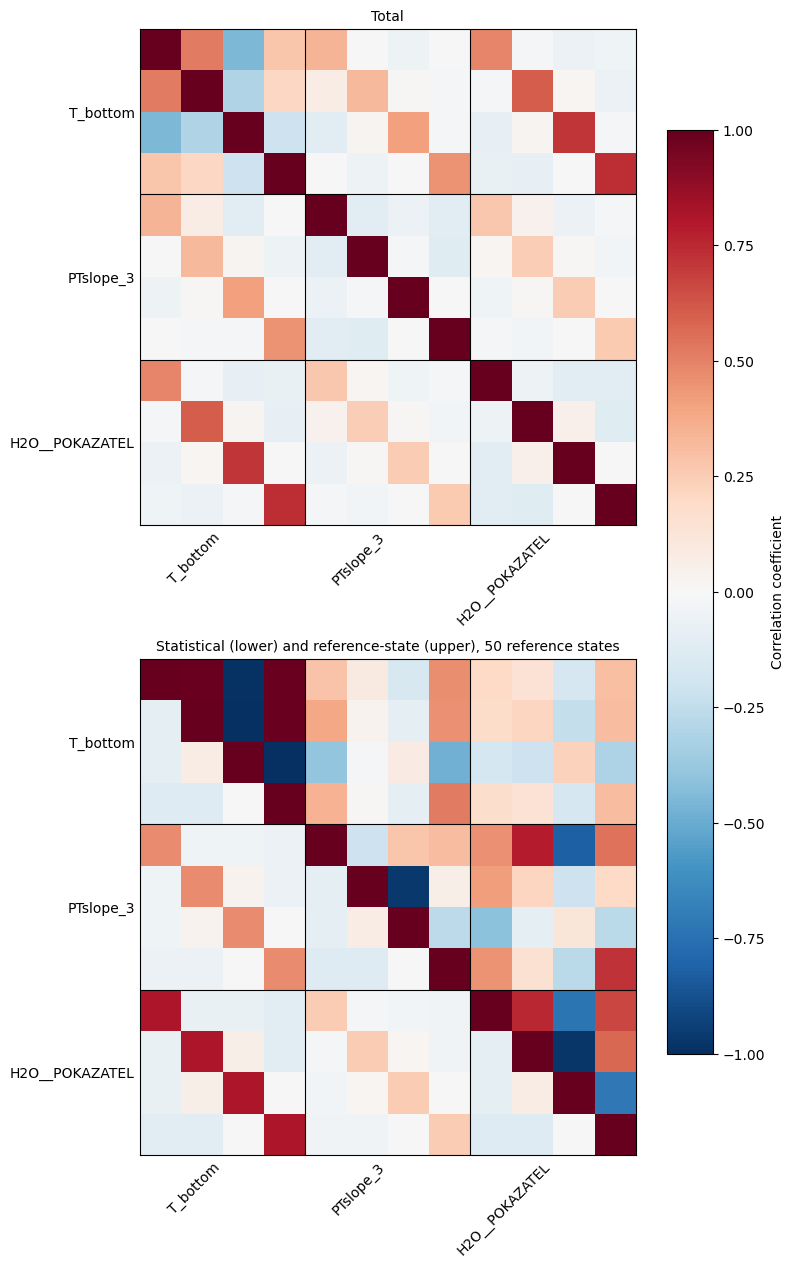

In [22]:
figure, axes = stage_2.plot_modulation_correlation(
    sample_dict={stage_2_configuration.retrieval_name: stage_2_samples},
    parameters_read=stage_2_names,
)

### What the modulation means for the atmosphere

Two of our modulated parameters, `T_bottom` and `PTslope_3`, set the temperature profile, so their modulation is a change of the temperature with time.
`plot_modulation_temperature` shifts the modulated parameters through one rotation, evaluates the temperature profile of the model at every phase, and shows how far it departs from its rotation average.
It works for any temperature parameterisation, because it uses the model function itself.
We mark the pressure at which `PTslope_3` sets the temperature gradient.


Plotting the temperature modulation of 'NIRSpec_time_series'
  0.0001 bar: median peak-to-peak 2.84 K
  0.000971 bar: median peak-to-peak 3.46 K
  0.00943 bar: median peak-to-peak 3.65 K
  1.06 bar: median peak-to-peak 4.49 K
  10.3 bar: median peak-to-peak 6.63 K
  100 bar: median peak-to-peak 10.4 K


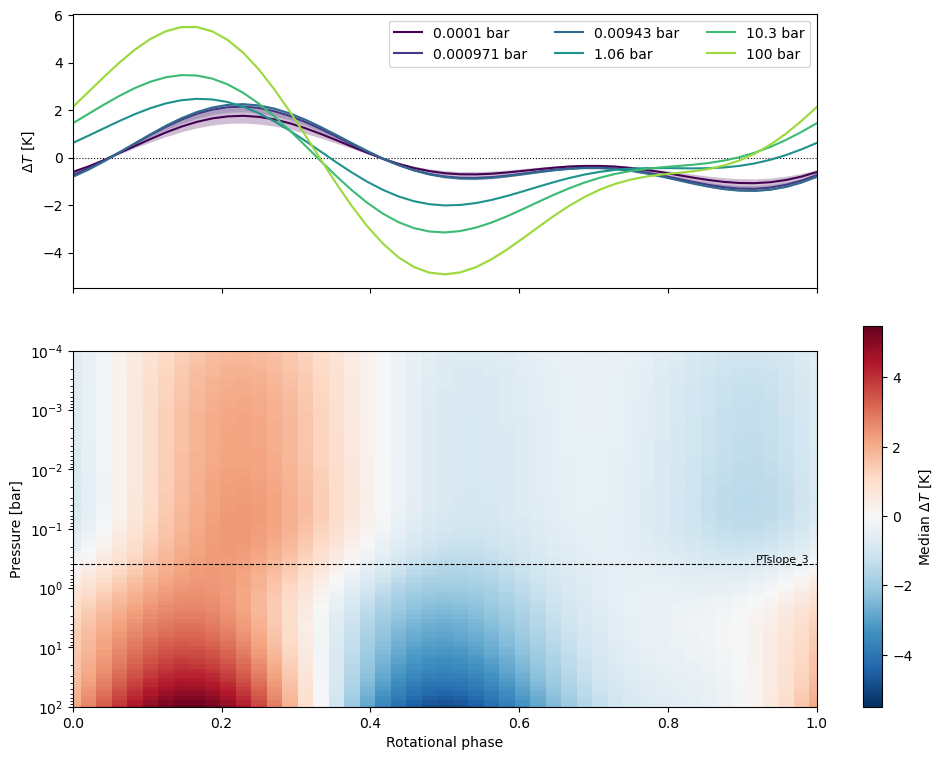

In [23]:
gradient_node_pressures = np.logspace(-4.0, 2.0, n_layers)  # PTslope_1 at the bottom, PTslope_6 at the top

figure, axes = stage_2.plot_modulation_temperature(
    sample_dict={stage_2_configuration.retrieval_name: stage_2_samples},
    parameters_read=stage_2_names,
    pressure_markers={"PTslope_3": gradient_node_pressures[n_layers - 3]},
)

### Comparing with the data

Finally, let's check how well the modulation describes the data themselves.
`plot_modulation_light_curves` compares the data with the model in a few wavelength bands, and `plot_modulation_map` does the same for every wavelength at once: it divides every spectrum by its time average, folds the result on the rotation period, and shows the data, the model and their difference.
Both use a single reference atmosphere, here the best fit of stage 1, and share one solve.
The model should leave nothing behind but noise.


Plotting the light curves of 'NIRSpec_time_series'
  0.9-1.4: model peak-to-peak 2.13%, rms(data - model) 0.0529%, median uncertainty 0.0523%
  1.4-1.8: model peak-to-peak 1.63%, rms(data - model) 0.0718%, median uncertainty 0.0694%
  2-2.5: model peak-to-peak 1.77%, rms(data - model) 0.0715%, median uncertainty 0.073%
  3-4: model peak-to-peak 1.13%, rms(data - model) 0.0662%, median uncertainty 0.0643%
  4-5.3: model peak-to-peak 0.926%, rms(data - model) 0.0639%, median uncertainty 0.065%


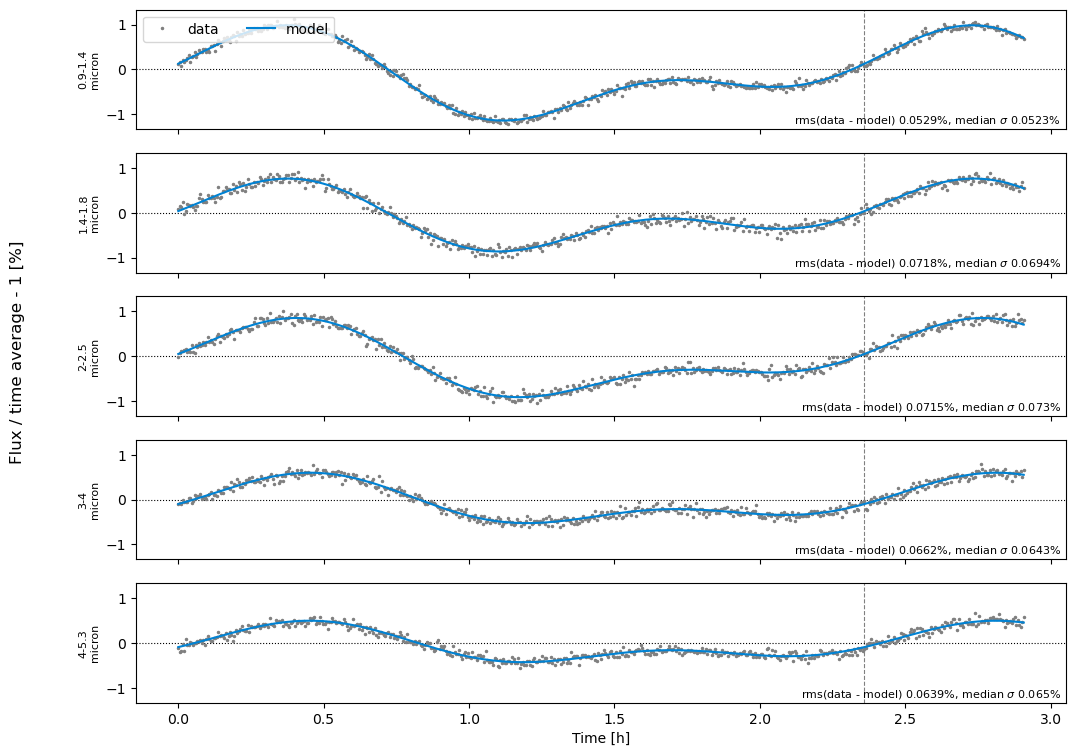

In [24]:
reference_atmosphere = {**best_fit, "period": best_period}

figure, axes = stage_2.plot_modulation_light_curves(
    parameters=reference_atmosphere,
    bands=((0.9, 1.4), (1.4, 1.8), (2.0, 2.5), (3.0, 4.0), (4.0, 5.3)),
    refresh=True,
)


Plotting the variability map of 'NIRSpec_time_series'
  data: rms 0.513%
  model: rms 0.502%
  residual (data - model): rms 0.108%


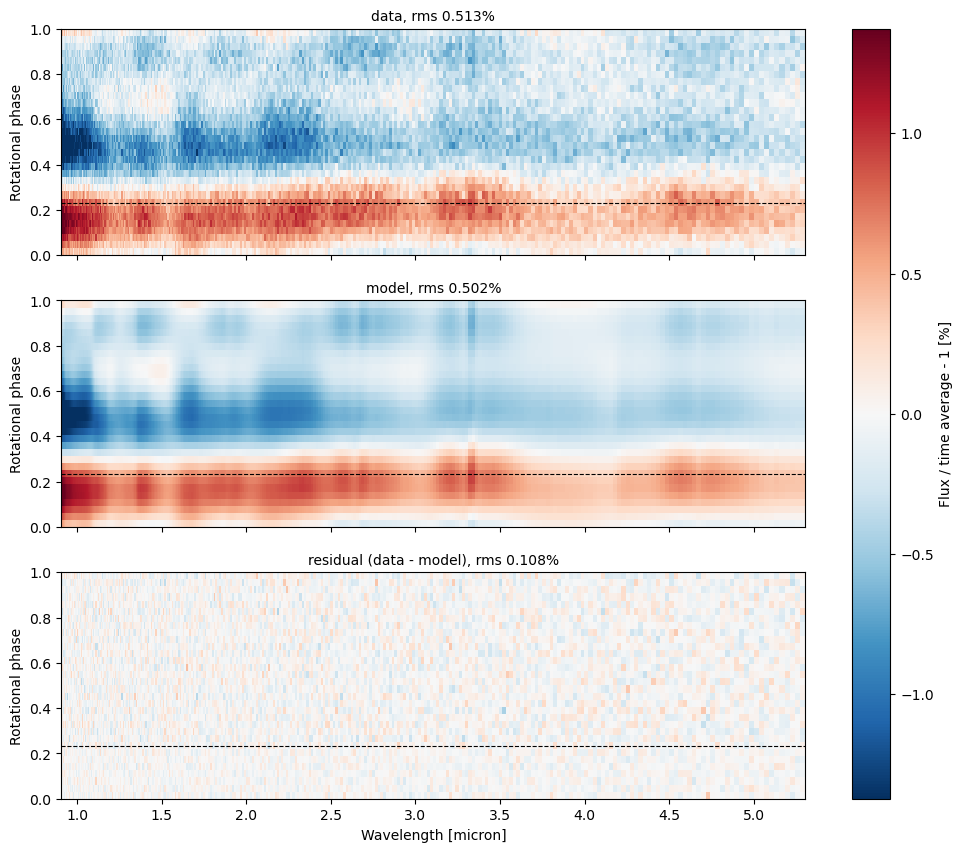

In [25]:
figure, axes = stage_2.plot_modulation_map(parameters=reference_atmosphere)

## Before you trust the result

The linearised model is an approximation, so a few checks belong with any published result.
They are described in detail on the ["Linearised Time-Series Retrievals"](../retrieval_linearised_time_series.html) page; in short:

- **Is the linear approximation good enough?** What biases an amplitude is not the size of the second-order error, but how much of it looks like the signal. `linearised.amplitude_bias_projection` measures exactly that, in units of the amplitude uncertainties. With a synthetic dataset like ours, you can also simply compare the retrieved amplitudes with the truth.
- **Are the prior widths affecting the result?** The marginal likelihood depends on the widths given in `modulated_parameters`. If you compare models, for example different sets of modulated parameters, check with `linearised.evidence_prior_scan` that the conclusion does not change over a range of reasonable widths.
- **Can the data distinguish the parameters?** If two response spectra look alike, only a combination of the two parameters is measured. `linearised.posterior_eigenspectrum` shows which combinations the data actually determine.

## Using real data

To retrieve the real SIMP 0136 time series, replace the synthetic arrays with your own reduced data: the integration times in seconds, and the spectra and their uncertainties as `(n_epochs, n_wavelengths)` arrays, together with the spectral resolution of every channel.
Everything else stays the same. A few things are worth knowing:

- The forward model will not fit a real spectrum to 0.02%, so the error floor in stage 1 is essential, and it should be a free parameter: `is_free_parameter=True` with a prior such as `tfpd.Uniform(low=-5.0, high=-1.0)`. For SIMP 0136 it settles at around ten percent.
- Real retrievals of the static atmosphere can have several separated solutions, and a Laplace approximation describes only one of them. Start a sampler from the optimal estimate, and run it twice with different `seed` values: that is the most reliable way we know of to check that it found the best solution.
- `add_linearised_time_series_data` can also model noise that is correlated in time (`noise_correlation_time`), and slowly varying model errors (`nuisance_response_modes`).

**Contact**

If you need any additional help, don't hesitate to contact [Evert Nasedkin](mailto:nasedkinevert@gmail.com?subject=[petitRADTRANS]%20Retrievals).